In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc

In [3]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker
import pandas as pd

In [4]:
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

ERROR 1: PROJ: proj_create_from_database: Open of /g/data/xp65/public/./apps/med_conda/envs/analysis3-25.09/share/proj failed


In [5]:
import cmocean
from scipy import stats

In [6]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 14
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 0.8
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [7]:
def plot_decorator():
    ax = plt.gca()
    
    # Minor ticks
    # ax.minorticks_on()
    # plt.tick_params(which='minor', axis='x', bottom=False)
    
    # Grid (light, behind data)
    ax.grid(color='gray', lw=0.4, alpha=0.1)
    
    # Remove top/right spines (Nature style)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Tight layout
    # plt.tight_layout()

In [8]:
from matplotlib.colors import BoundaryNorm as BM
# from matplotlib.colors import LogNorm as LM
import matplotlib.patches as mpatches

In [9]:
import regionmask

In [10]:
def plot_background(ax, draw_labels=False, draw_ipcc_regions=False):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=draw_labels,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    if draw_ipcc_regions:
        ar6_reg = regionmask.defined_regions.ar6.all

        # Plot the region boundaries, passing the same 'ax'
        # Use 'line_kws' to customize line properties (color, thickness, etc.)
        ar6_reg.plot_regions(
            ax=ax,
            line_kws=dict(color='black', lw=1.0, alpha=0.4),
            text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
            add_label=False, # Set to True to add text labels for regions
        )
    return ax




def plot_maps(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='///', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] > 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] <= 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_map(x, y, z, title, label, cmap, levels, add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        if hatch_type == 'insig':
            pval_plot = np.ma.masked_less_equal(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='//', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval > 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        elif hatch_type == 'sig':
            pval_plot = np.ma.masked_greater(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='..', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval <= 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [11]:
def plot_maps_no_proj(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_colorbar=True, auto_aspect=False, draw_clabel=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, sharex=True, sharey=True)
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle')
    
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            cs = axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, alpha=0.5)
            if draw_clabel:
                axlist[i].clabel(cs, inline=True, fontsize=8)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])
    return fig, axlist

In [12]:
def plot_maps_tele_delta(x, y, z, titles, labels, cmap, levels, pval = [], pval2=[], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 1.5)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
        if pval2 != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 1.5)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='xxx', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval[i] <= 0.05, True, False)
            # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_tele_delta(x, y, z, title, label, cmap, levels, add_sign=False, pval = [],  pval2 = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        pval_plot = np.ma.masked_less_equal(pval, 1)
        ax.pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
        pval_plot = np.ma.masked_less_equal(pval2, 1)
        ax.pcolor(x, y, pval_plot, alpha = 0., hatch='xxx', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [13]:
import matplotlib.colors as mcolors

In [14]:
def plot_teleconnection_robustness(
    field,                     # xarray DataArray (lat, lon)
    lon, lat,                 # coordinates
    snr_model=None,           # SNR from SMILE (optional)
    snr_obs=None,             # SNR from observations (optional)
    pval_model=None,          # p-values from CMIP6 t-test (optional)
    snr_threshold=1.5,
    pval_threshold=0.05,
    use_pval=False,           # switch: True for CMIP6, False for SMILE
    cmap='RdBu_r',
    vmin=None,
    vmax=None,
    title_main='',
    title_suffix='',
    cbar_label='',
    stipple_style='dots'      # 'dots' or 'hatch'
):
    import numpy as np
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs
    import matplotlib.colors as mcolors

    xx, yy = np.meshgrid(lon, lat)

    # ---------------------------
    # Define robustness masks
    # ---------------------------
    if use_pval:
        if pval_model is None:
            raise ValueError("pval_model must be provided when use_pval=True")

        mask_model = pval_model <= pval_threshold
        if snr_obs is None:
            mask_obs = None  # usually not applicable for CMIP6
        else:
            mask_obs = snr_obs > snr_threshold
    else:
        if snr_model is None or snr_obs is None:
            raise ValueError("snr_model and snr_obs must be provided when use_pval=False")

        mask_model = snr_model > snr_threshold
        mask_obs   = snr_obs > snr_threshold

    # Combined mask
    if mask_obs is not None:
        mask_both = mask_model & mask_obs
    else:
        mask_both = mask_model

    # ---------------------------
    # Categorical map
    # ---------------------------
    if mask_obs is not None:
        robust_cat = (mask_model.astype(int) + 2 * mask_obs.astype(int))
        # 0 none, 1 model, 2 obs, 3 both
    else:
        robust_cat = mask_model.astype(int)  # binary only

    # ---------------------------
    # Plot
    # ---------------------------
    fig = plt.figure(figsize=(12,5))

    # ===========================
    # Panel A: field + robustness
    # ===========================
    ax1 = plt.subplot(1,2,1, projection=ccrs.PlateCarree(central_longitude=180))

    field.plot(
        ax=ax1,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        cbar_kwargs=dict(
            orientation='horizontal',
            shrink=0.8,
            aspect=40,
            pad=0.05,
            label=cbar_label
        ),
        transform=ccrs.PlateCarree()
    )

    # Overlay robustness
    if stipple_style == 'dots':
        ax1.scatter(xx[mask_both], yy[mask_both],
                    s=2, color='k', marker='.',
                    transform=ccrs.PlateCarree())
    else:
        stip = np.ma.masked_where(~mask_both, mask_both)
        ax1.pcolor(xx, yy, stip, hatch='...', alpha=0.,
                   transform=ccrs.PlateCarree())

    ax1.set_title(title_main)
    plot_background(ax1)

    # ===========================
    # Panel B: categorical map
    # ===========================
    ax2 = plt.subplot(1,2,2, projection=ccrs.PlateCarree(central_longitude=180))

    if mask_obs is not None:
        cmap_cat = mcolors.ListedColormap([
            'lightgrey',   # none
            'tab:blue',    # model only
            'tab:orange',  # obs only
            'tab:red'      # both
        ])
        bounds = [0,1,2,3,4]
        ticks = [0.5,1.5,2.5,3.5]
        labels = ['None', 'Model only', 'Obs only', 'Both']
    else:
        cmap_cat = mcolors.ListedColormap([
            'lightgrey',
            'tab:red'
        ])
        bounds = [0,1,2]
        ticks = [0.5,1.5]
        labels = ['Not robust', 'Robust']

    norm = mcolors.BoundaryNorm(bounds, cmap_cat.N)

    im = ax2.pcolormesh(
        xx, yy, robust_cat,
        cmap=cmap_cat,
        norm=norm,
        transform=ccrs.PlateCarree()
    )

    cbar = plt.colorbar(im, ax=ax2, orientation='horizontal', pad=0.05, shrink=0.8)
    cbar.set_ticks(ticks)
    cbar.set_ticklabels(labels)

    ax2.set_title(title_suffix)
    plot_background(ax2)

    plt.tight_layout()
    plt.show()

In [15]:
import sys

In [16]:
# sys.path.append('./PhD/enso_teleconnection_robustness/')

In [17]:
from functions import preproc_funcs as funcs

In [18]:
model_list = [
    'ACCESS-ESM1-5',
    'CESM1-CAM5',
    'CSIRO-Mk3-6-0',
    'CanESM2',
    'CanESM5_p1',
    'GFDL-CM3',
    'GFDL-ESM2M',
    'GFDL-SPEAR-MED',
    'MIROC6',
    'MPI-ESM',
    
]

In [62]:
pr_regr_obs_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_obs_1950_2014.nc')
pr_regr_rean_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_rean_1950_2014.nc')

pr_regr_obs_30y = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30.nc')
pr_regr_rean_30y = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30_rean.nc')

In [63]:
delta_pr_regr_obs = (pr_regr_obs_30y.regr - pr_regr_obs_baseline.regr)
delta_pr_regr_rean = (pr_regr_rean_30y.regr - pr_regr_rean_baseline.regr)

In [64]:
pr_regr_cmip6_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/pr/cmip6_regr_baseline.nc')
pr_regr_cmip6_midc = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/pr/cmip6_regr_mid_century.nc')
pr_regr_cmip6_endc = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/pr/cmip6_regr_end_century.nc')

In [65]:
delta_pr_regr_cmip6_midc  = (pr_regr_cmip6_midc.regr - pr_regr_cmip6_baseline.regr)
delta_pr_regr_cmip6_endc  = (pr_regr_cmip6_endc.regr - pr_regr_cmip6_baseline.regr)

In [66]:
ts_regr_cmip6_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_baseline.nc')
ts_regr_cmip6_midc = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_mid_century.nc')
ts_regr_cmip6_endc = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_end_century.nc')

In [67]:
delta_ts_regr_cmip6_midc  = (ts_regr_cmip6_midc.regr - ts_regr_cmip6_baseline.regr)
delta_ts_regr_cmip6_endc  = (ts_regr_cmip6_endc.regr - ts_regr_cmip6_baseline.regr)

In [68]:
model = model_list[1]
model

'CESM1-CAM5'

In [69]:
def _preprocess(da):
    if 'height' in da.coords:
        da = da.drop('height')
    return da

In [70]:

## calculating model_uncertainty and internal variabiltiy uncertainty
pr_regr_smile_baseline_means = []
pr_regr_smile_baseline_vars = []

delta_pr_regr_smile_midc_means = []
delta_pr_regr_smile_midc_vars = []

delta_pr_regr_smile_endc_means = []
delta_pr_regr_smile_endc_vars = []


for model in model_list:
    pr_regr_smile_baseline = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_baseline.nc', preprocess=_preprocess).regr
    pr_regr_smile_baseline_means.append(pr_regr_smile_baseline.mean('model'))
    pr_regr_smile_baseline_vars.append(pr_regr_smile_baseline.var('model'))
    #
    delta_pr_regr_smile_midc = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_mid_century.nc', preprocess=_preprocess).regr - pr_regr_smile_baseline
    delta_pr_regr_smile_midc_means.append(delta_pr_regr_smile_midc.mean('model'))
    delta_pr_regr_smile_midc_vars.append(delta_pr_regr_smile_midc.var('model'))
    #
    delta_pr_regr_smile_endc = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_end_century.nc', preprocess=_preprocess).regr - pr_regr_smile_baseline
    delta_pr_regr_smile_endc_means.append(delta_pr_regr_smile_endc.mean('model'))
    delta_pr_regr_smile_endc_vars.append(delta_pr_regr_smile_endc.var('model'))
    #
    print(f'Completed {model}')


pr_regr_smile_baseline_means = xr.concat(pr_regr_smile_baseline_means, dim='smile')
pr_regr_smile_baseline_means['smile'] = model_list
pr_regr_smile_baseline_vars = xr.concat(pr_regr_smile_baseline_vars, dim='smile')
pr_regr_smile_baseline_vars['smile'] = model_list


delta_pr_regr_smile_midc_means = xr.concat(delta_pr_regr_smile_midc_means, dim='smile').load()
delta_pr_regr_smile_midc_means['smile'] = model_list
delta_pr_regr_smile_midc_vars = xr.concat(delta_pr_regr_smile_midc_vars, dim='smile').load()
delta_pr_regr_smile_midc_vars['smile'] = model_list

delta_pr_regr_smile_endc_means = xr.concat(delta_pr_regr_smile_endc_means, dim='smile').load()
delta_pr_regr_smile_endc_means['smile'] = model_list
delta_pr_regr_smile_endc_vars = xr.concat(delta_pr_regr_smile_endc_vars, dim='smile').load()
delta_pr_regr_smile_endc_vars['smile'] = model_list
print('DONE')

Completed ACCESS-ESM1-5
Completed CESM1-CAM5
Completed CSIRO-Mk3-6-0
Completed CanESM2
Completed CanESM5_p1
Completed GFDL-CM3
Completed GFDL-ESM2M
Completed GFDL-SPEAR-MED
Completed MIROC6
Completed MPI-ESM
DONE


In [71]:
## calculating model_uncertainty and internal variabiltiy uncertainty
pr_regr_smile_baseline_pvals = []
delta_pr_regr_smile_midc_pvals = []

delta_pr_regr_smile_endc_pvals = []

# delta_pr_regr_smile_regr15_pvals = []
# delta_pr_regr_smile_regr15_vars = []

# delta_pr_regr_smile_regr20_pvals = []
# delta_pr_regr_smile_regr20_vars = []

# delta_pr_regr_smile_regr30_pvals = []
# delta_pr_regr_smile_regr30_vars = []

# delta_pr_regr_smile_regr40_pvals = []
# delta_pr_regr_smile_regr40_vars = []



for model in model_list:
    pr_regr_smile_baseline_pval = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_baseline.nc', preprocess=_preprocess).pval
    pr_regr_smile_baseline_pvals.append(pr_regr_smile_baseline_pval)
    #
    delta_pr_regr_smile_midc_pval = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_mid_century.nc', preprocess=_preprocess).pval
    delta_pr_regr_smile_midc_pvals.append(delta_pr_regr_smile_midc_pval)
    #
    delta_pr_regr_smile_endc_pval = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_end_century.nc', preprocess=_preprocess).pval
    delta_pr_regr_smile_endc_pvals.append(delta_pr_regr_smile_endc_pval)
    # #
    # delta_pr_regr_smile_regr15 = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr15.nc', preprocess=_preprocess).regr - pr_regr_smile_baseline
    # delta_pr_regr_smile_regr15_pvals.append(delta_pr_regr_smile_regr15.mean('model'))
    # delta_pr_regr_smile_regr15_vars.append(delta_pr_regr_smile_regr15.var('model'))
    # #
    # delta_pr_regr_smile_regr20 = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr20.nc', preprocess=_preprocess).regr - pr_regr_smile_baseline
    # delta_pr_regr_smile_regr20_pvals.append(delta_pr_regr_smile_regr20.mean('model'))
    # delta_pr_regr_smile_regr20_vars.append(delta_pr_regr_smile_regr20.var('model'))
    # #
    # delta_pr_regr_smile_regr30 = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr30.nc', preprocess=_preprocess).regr - pr_regr_smile_baseline
    # delta_pr_regr_smile_regr30_pvals.append(delta_pr_regr_smile_regr30.mean('model'))
    # delta_pr_regr_smile_regr30_vars.append(delta_pr_regr_smile_regr30.var('model'))
    # #
    # delta_pr_regr_smile_regr40 = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr40.nc', preprocess=_preprocess).regr - pr_regr_smile_baseline
    # delta_pr_regr_smile_regr40_pvals.append(delta_pr_regr_smile_regr40.mean('model'))
    # delta_pr_regr_smile_regr40_vars.append(delta_pr_regr_smile_regr40.var('model'))
    #
    print(f'Completed {model}')


pr_regr_smile_baseline_pvals = xr.concat(pr_regr_smile_baseline_pvals, dim='smile').load()
pr_regr_smile_baseline_pvals['smile'] = model_list

delta_pr_regr_smile_midc_pvals = xr.concat(delta_pr_regr_smile_midc_pvals, dim='smile').load()
delta_pr_regr_smile_midc_pvals['smile'] = model_list

delta_pr_regr_smile_endc_pvals = xr.concat(delta_pr_regr_smile_endc_pvals, dim='smile').load()
delta_pr_regr_smile_endc_pvals['smile'] = model_list

# delta_pr_regr_smile_regr15_pvals = xr.concat(delta_pr_regr_smile_regr15_pvals, dim='smile').load()
# delta_pr_regr_smile_regr15_pvals['smile'] = model_list
# delta_pr_regr_smile_regr15_vars = xr.concat(delta_pr_regr_smile_regr15_vars, dim='smile').load()
# delta_pr_regr_smile_regr15_vars['smile'] = model_list

# delta_pr_regr_smile_regr20_pvals = xr.concat(delta_pr_regr_smile_regr20_pvals, dim='smile').load()
# delta_pr_regr_smile_regr20_pvals['smile'] = model_list
# delta_pr_regr_smile_regr20_vars = xr.concat(delta_pr_regr_smile_regr20_vars, dim='smile').load()
# delta_pr_regr_smile_regr20_vars['smile'] = model_list

# delta_pr_regr_smile_regr30_pvals = xr.concat(delta_pr_regr_smile_regr30_pvals, dim='smile').load()
# delta_pr_regr_smile_regr30_pvals['smile'] = model_list
# delta_pr_regr_smile_regr30_vars = xr.concat(delta_pr_regr_smile_regr30_vars, dim='smile').load()
# delta_pr_regr_smile_regr30_vars['smile'] = model_list

# delta_pr_regr_smile_regr40_pvals = xr.concat(delta_pr_regr_smile_regr40_pvals, dim='smile').load()
# delta_pr_regr_smile_regr40_pvals['smile'] = model_list
# delta_pr_regr_smile_regr40_vars = xr.concat(delta_pr_regr_smile_regr40_vars, dim='smile').load()
# delta_pr_regr_smile_regr40_vars['smile'] = model_list

print('DONE')

Completed ACCESS-ESM1-5
Completed CESM1-CAM5
Completed CSIRO-Mk3-6-0
Completed CanESM2
Completed CanESM5_p1
Completed GFDL-CM3
Completed GFDL-ESM2M
Completed GFDL-SPEAR-MED
Completed MIROC6
Completed MPI-ESM
DONE


### All existing datasets


1. OBS 30-year uncertainty - Var(delta_pr_regr_obs)
2. REAN 30-year uncertainty - Var(delta_pr_regr_rean)
3. SMILE 30-year internal variability uncertainty - Mean(delta_pr_regr_smile_endc_vars)
4. SMILE 30-year model uncertainty - Var(delta_pr_regr_smile_endc_means)
5. CMIP6 30-year model uncertainty only - Var(delta_pr_regr_cmip6_endc) (this is a measure of **model uncertainty** and can be used to constrain SMILE uncertainty)

In [72]:
import xesmf as xe

In [73]:
regridder_rean = xe.Regridder(pr_regr_rean_baseline, pr_regr_cmip6_baseline, 'bilinear', periodic=True, ignore_degenerate=True)
regridder_obs = xe.Regridder(pr_regr_obs_baseline, pr_regr_cmip6_baseline, 'bilinear', periodic=True, ignore_degenerate=True)

In [74]:
def plot_baseline_teleconnection(
    field,
    lon,
    lat,
    sig_data,          # p-values (NOT binary)
    mode='cmip6',      # 'cmip6' or 'smile'
    p_threshold=0.05,
    agreement_threshold=0.8,
    # smile_threshold=0.55,   # NEW (minimal addition)
    cmap='RdBu_r',
    vmin=-1.0,
    vmax=1.0,
    cbar_label='Regression (degC/degC)',
    title='1950–2014',
):

    xx, yy = np.meshgrid(lon, lat)

    plt.figure(figsize=(6,5))
    ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))

    field.plot(
        ax=ax,
        vmin=vmin, vmax=vmax,
        cmap=cmap,
        cbar_kwargs=dict(
            orientation='horizontal',
            shrink=0.8,
            aspect=40,
            pad=0.025,
            label=cbar_label
        ),
        transform=ccrs.PlateCarree()
    )

    # ---------------------------
    # Convert p-values → binary significance
    # ---------------------------
    sig = sig_data <= p_threshold

    # ---------------------------
    # Agreement calculation
    # ---------------------------
    if mode == 'cmip6':
        agreement = sig.mean('model')

    elif mode == 'smile':

        # # STEP 1: ensemble-level agreement per model
        # if 'model' in sig.dims:
        #     model_level = sig.mean('model')   # (model, lat, lon)
        # else:
        #     model_level = sig

        # # STEP 2: FILTER models (NEW PART)
        # model_level = model_level >= smile_threshold  # 0.55 rule

        # # STEP 3: fraction of SMILEs passing filter
        # agreement = model_level.mean('smile')

        sig_stacked = sig.stack(ensemble = ("model", "smile"))
        agreement = sig_stacked.mean('ensemble')

    else:
        raise ValueError("mode must be 'cmip6' or 'smile'")

    # ---------------------------
    # Stippling mask
    # ---------------------------
    mask = agreement >= agreement_threshold

    ax.scatter(
        xx[mask],
        yy[mask],
        s=1,
        marker='.',
        color='k',
        transform=ccrs.PlateCarree(),
        zorder=5
    )

    ax.set_title(title)
    plot_background(ax)

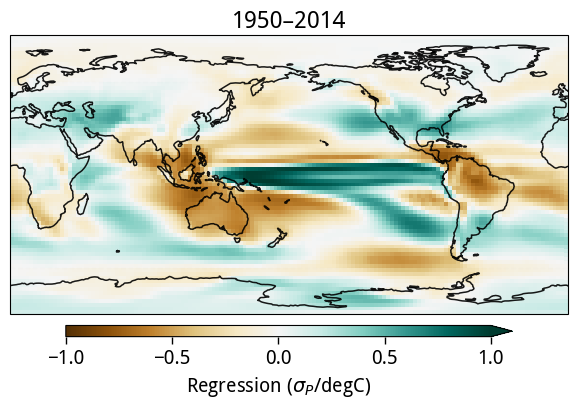

In [75]:
zz = pr_regr_smile_baseline_means.mean('smile')
sig_smiles = pr_regr_smile_baseline_pvals

plot_baseline_teleconnection(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    sig_data=sig_smiles,          # p-values (NOT binary)
    mode='smile',      # 'cmip6' or 'smile'
    p_threshold=0.05,
    agreement_threshold=0.8,
    # smile_threshold=0.25,
    cmap='BrBG',
    cbar_label='Regression ($\sigma_P$/degC)',
    vmin=-1.0,
    vmax=1.0,
    title='1950–2014',
)

plt.tight_layout()
plt.show()

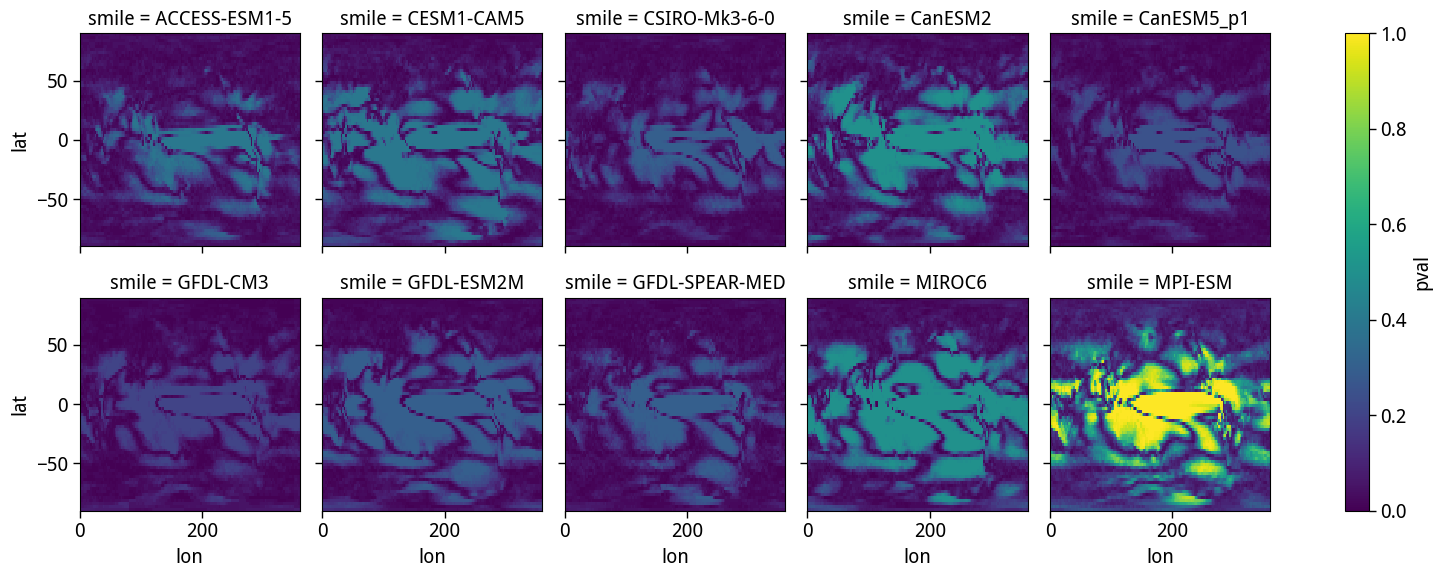

In [76]:
(pr_regr_smile_baseline_pvals <= 0.05).mean('model').plot(col='smile', col_wrap=5)

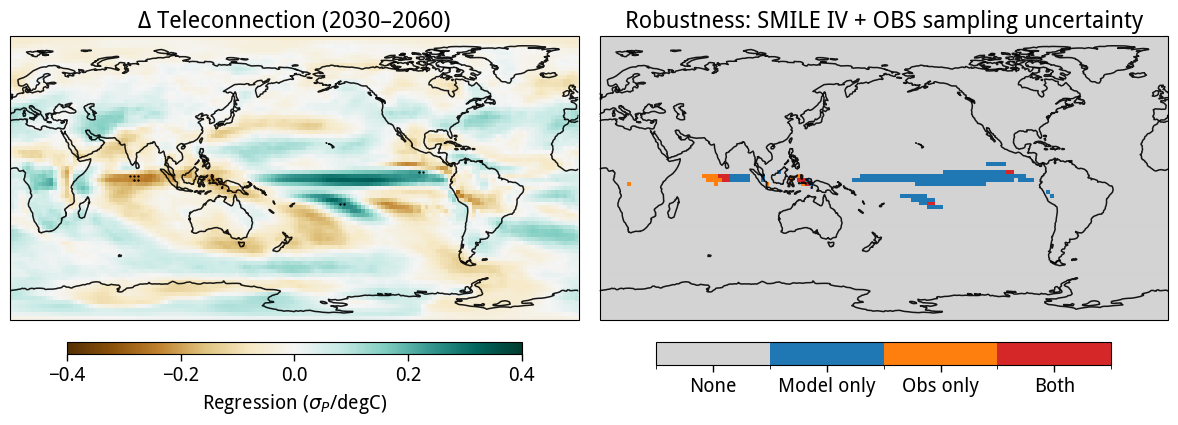

In [87]:
zz = delta_pr_regr_smile_midc_means.mean('smile')
# zp = ttest_ind3d(pr_regr_smile_baseline_means.load(), delta_pr_regr_smile_midc_means.load(), dim='smile')
zp1 = (np.abs(delta_pr_regr_smile_midc_means.mean('smile'))/np.sqrt((pr_regr_smile_baseline_vars).mean('smile')))
zp2 = (np.abs(delta_pr_regr_smile_midc_means.mean('smile'))/np.sqrt((regridder_rean(delta_pr_regr_rean)).var('ey')))
xx, yy = np.meshgrid(zz.lon, zz.lat)


plot_teleconnection_robustness(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    snr_model=zp1,
    snr_obs=zp2,
    snr_threshold=1.5,
    use_pval=False,
    vmin=-0.4,
    vmax=0.4,
    cmap='BrBG',
    cbar_label='Regression ($\sigma_P$/degC)',
    title_main='Δ Teleconnection (2030–2060)',
    title_suffix = 'Robustness: SMILE IV + OBS sampling uncertainty',
)

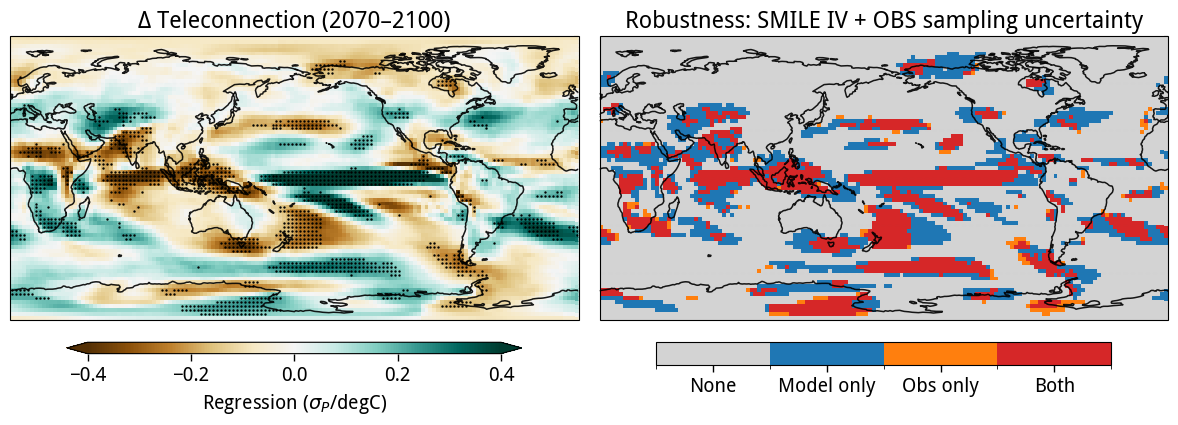

In [88]:
zz = delta_pr_regr_smile_endc_means.mean('smile')
# zp = ttest_ind3d(pr_regr_smile_baseline_means.load(), delta_pr_regr_smile_endc_means.load(), dim='smile')
zp1 = (np.abs(delta_pr_regr_smile_endc_means.mean('smile'))/np.sqrt((pr_regr_smile_baseline_vars).mean('smile')))
zp2 = (np.abs(delta_pr_regr_smile_endc_means.mean('smile'))/np.sqrt((regridder_rean(delta_pr_regr_rean)).var('ey')))
xx, yy = np.meshgrid(zz.lon, zz.lat)


plot_teleconnection_robustness(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    snr_model=zp1,
    snr_obs=zp2,
    snr_threshold=1.0,
    use_pval=False,
    vmin=-0.4,
    vmax=0.4,
    cmap='BrBG',
    cbar_label='Regression ($\sigma_P$/degC)',
    title_main='Δ Teleconnection (2070–2100)',
    title_suffix = 'Robustness: SMILE IV + OBS sampling uncertainty',
)

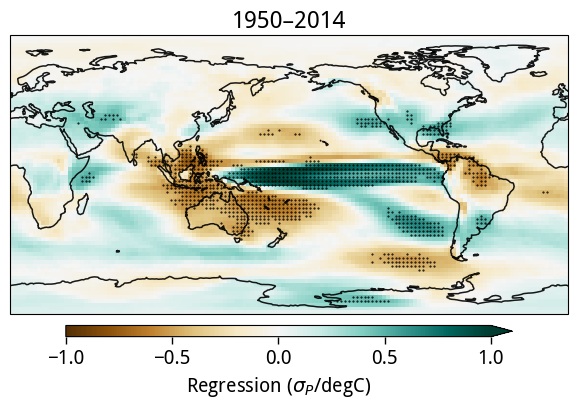

In [89]:
zz = pr_regr_cmip6_baseline.regr.mean('model')
sig_cmip6 = pr_regr_cmip6_baseline.pval

plot_baseline_teleconnection(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    sig_data=sig_cmip6,          # p-values (NOT binary)
    mode='cmip6',      # 'cmip6' or 'smile'
    p_threshold=0.05,
    agreement_threshold=0.8,
    vmin=-1.0,
    vmax=1.0,
    cmap='BrBG',
    cbar_label='Regression ($\sigma_P$/degC)',
    title='1950–2014',
)

plt.tight_layout()
plt.show()

In [90]:
def ttest_ind1d(a, b):
    _, p = stats.ttest_ind(a,b, equal_var=False)
    return p


def ttest_ind3d(da1, da2, dim='model'):
    return xr.apply_ufunc(ttest_ind1d, da1, da2, input_core_dims=[[dim], [dim]], exclude_dims={dim, dim}, vectorize=True, dask='parallelized')

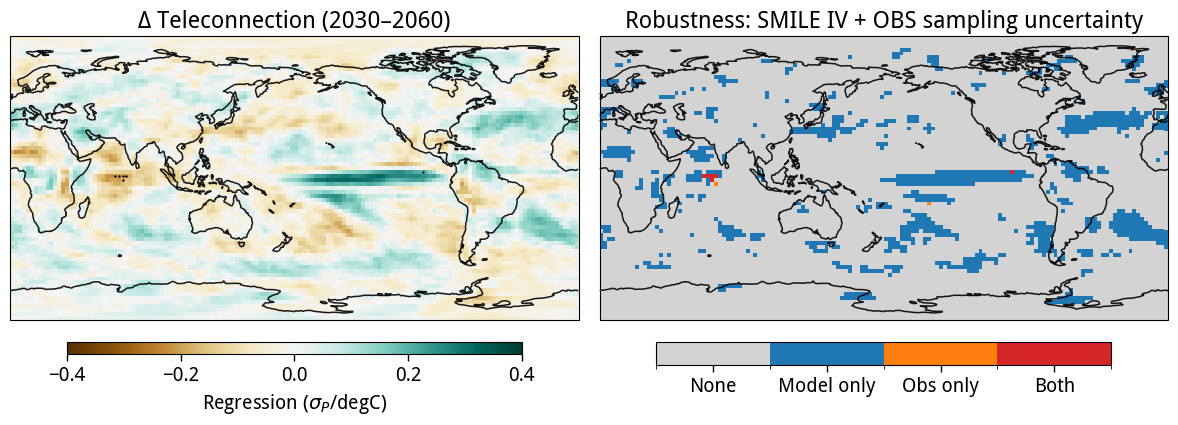

In [91]:
zz = delta_pr_regr_cmip6_midc.mean('model')
zp = ttest_ind3d(pr_regr_cmip6_baseline.regr, pr_regr_cmip6_midc.regr, dim='model')
zp1 = (np.abs(delta_pr_regr_cmip6_midc.mean('model'))/np.sqrt((pr_regr_cmip6_baseline.regr).var('model')))
# zp = (np.abs(delta_pr_regr_smile_midc_means.mean('smile'))/np.sqrt((delta_pr_regr_smile_midc_vars).mean('smile')))
zp2 = (np.abs(delta_pr_regr_cmip6_midc.mean('model'))/np.sqrt((regridder_rean(delta_pr_regr_rean)).var('ey')))
xx, yy = np.meshgrid(zz.lon, zz.lat)


plot_teleconnection_robustness(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    pval_model=zp,
    snr_obs=zp2,
    pval_threshold=0.05,
    use_pval=True,
    vmin=-0.4,
    vmax=0.4,
    cmap='BrBG',
    cbar_label='Regression ($\sigma_P$/degC)',
    title_main='Δ Teleconnection (2030–2060)',
    title_suffix = 'Robustness: SMILE IV + OBS sampling uncertainty',
)

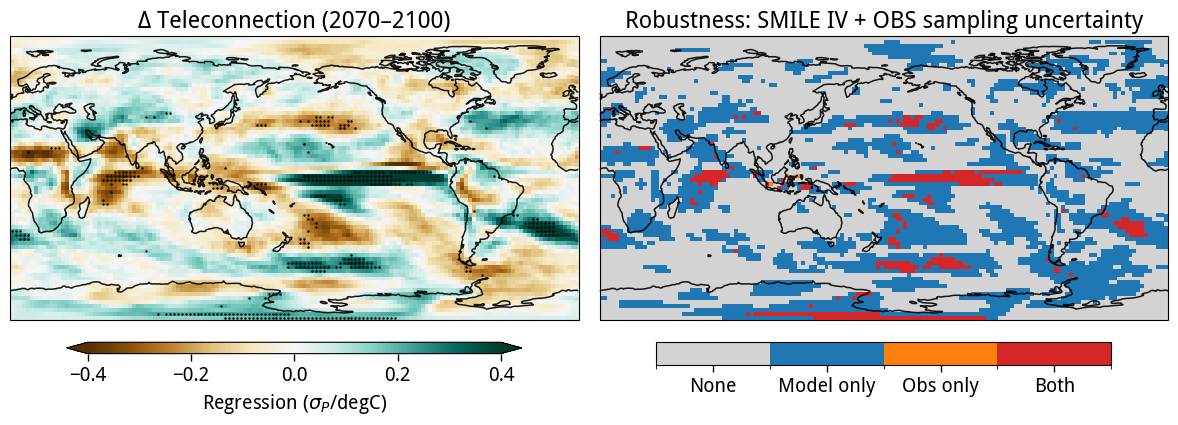

In [92]:
zz = delta_pr_regr_cmip6_endc.mean('model')
zp = ttest_ind3d(pr_regr_cmip6_baseline.regr, pr_regr_cmip6_endc.regr, dim='model')
zp1 = (np.abs(delta_pr_regr_cmip6_endc.mean('model'))/np.sqrt((pr_regr_cmip6_baseline.regr).var('model')))
# zp = (np.abs(delta_pr_regr_smile_endc_means.mean('smile'))/np.sqrt((delta_pr_regr_smile_endc_vars).mean('smile')))
zp2 = (np.abs(delta_pr_regr_cmip6_endc.mean('model'))/np.sqrt((regridder_rean(delta_pr_regr_rean)).var('ey')))
xx, yy = np.meshgrid(zz.lon, zz.lat)


plot_teleconnection_robustness(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    pval_model=zp,
    snr_obs=zp2,
    pval_threshold=0.05,
    use_pval=True,
    vmin=-0.4,
    vmax=0.4,
    cmap='BrBG',
    cbar_label='Regression ($\sigma_P$/degC)',
    title_main='Δ Teleconnection (2070–2100)',
    title_suffix = 'Robustness: SMILE IV + OBS sampling uncertainty',
)

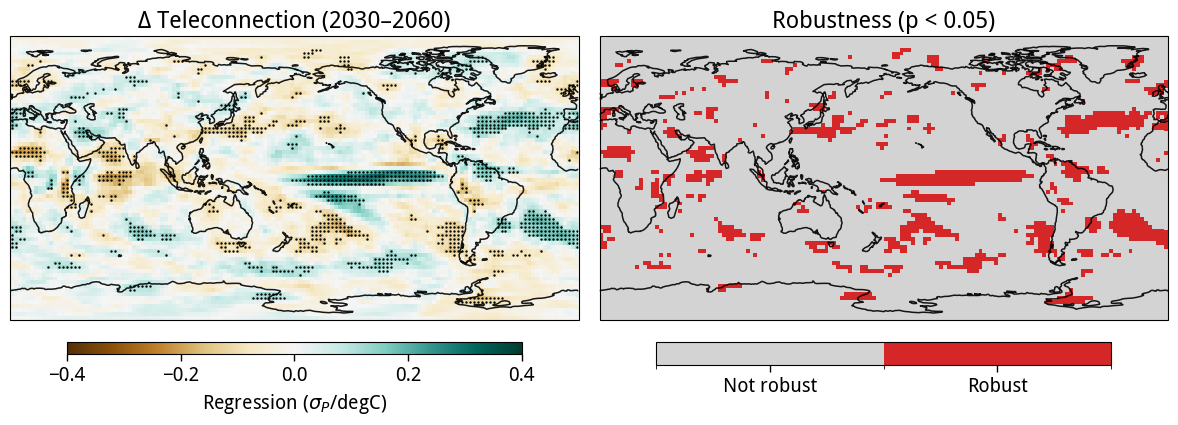

In [85]:
zz = delta_pr_regr_cmip6_midc.mean('model')
zp = ttest_ind3d(pr_regr_cmip6_baseline.regr, pr_regr_cmip6_midc.regr, dim='model')
zp1 = (np.abs(delta_pr_regr_cmip6_midc.mean('model'))/np.sqrt((pr_regr_cmip6_baseline.regr).var('model')))
# zp = (np.abs(delta_pr_regr_smile_midc_means.mean('smile'))/np.sqrt((delta_pr_regr_smile_midc_vars).mean('smile')))


plot_teleconnection_robustness(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    pval_model=zp,
    snr_obs=None,
    pval_threshold=0.05,
    use_pval=True,
    vmin=-0.4,
    vmax=0.4,
    cmap='BrBG',
    cbar_label='Regression ($\sigma_P$/degC)',
    title_main='Δ Teleconnection (2030–2060)',
    title_suffix='Robustness (p < 0.05)'
)

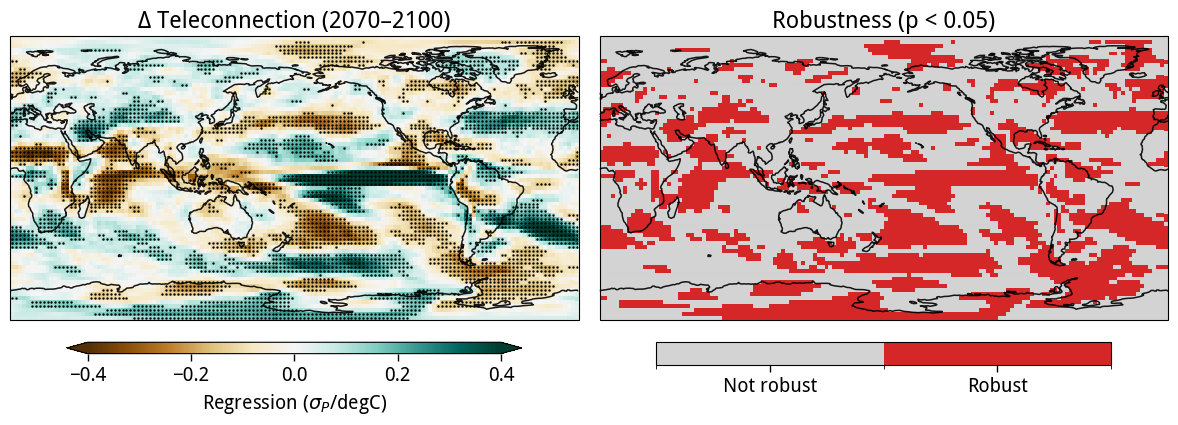

In [86]:
zz = delta_pr_regr_cmip6_endc.mean('model')
zp = ttest_ind3d(pr_regr_cmip6_baseline.regr, pr_regr_cmip6_endc.regr, dim='model')
zp1 = (np.abs(delta_pr_regr_cmip6_endc.mean('model'))/np.sqrt((pr_regr_cmip6_baseline.regr).var('model')))
# zp = (np.abs(delta_pr_regr_smile_endc_means.mean('smile'))/np.sqrt((delta_pr_regr_smile_endc_vars).mean('smile')))


plot_teleconnection_robustness(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    pval_model=zp,
    snr_obs=None,
    pval_threshold=0.05,
    use_pval=True,
    vmin=-0.4,
    vmax=0.4,
    cmap='BrBG',
    cbar_label='Regression ($\sigma_P$/degC)',
    title_main='Δ Teleconnection (2070–2100)',
    title_suffix='Robustness (p < 0.05)'
)

In [32]:
M_baseline = pr_regr_smile_baseline_means.var('smile')
I_baseline = pr_regr_smile_baseline_vars.mean('smile')
T_baseline = M_baseline + I_baseline

In [33]:
M_midc = delta_pr_regr_smile_midc_means.var('smile')
I_midc = delta_pr_regr_smile_midc_vars.mean('smile')
T_midc = M_midc + I_midc

In [34]:
M_endc = delta_pr_regr_smile_endc_means.var('smile')
I_endc = delta_pr_regr_smile_endc_vars.mean('smile')
T_endc = M_endc + I_endc

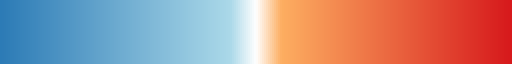

In [35]:
# Define colors
cmap = mcolors.LinearSegmentedColormap.from_list(
    "model_vs_internal",
    [
        (0.0, "#2c7bb6"),   # blue (internal variability dominates)
        (0.45, "#abd9e9"),  # light blue
        (0.50, "#ffffff"),  # neutral
        (0.55, "#fdae61"),  # light orange
        (1.0, "#d7191c"),   # red (model dominates)
    ]
)
cmap

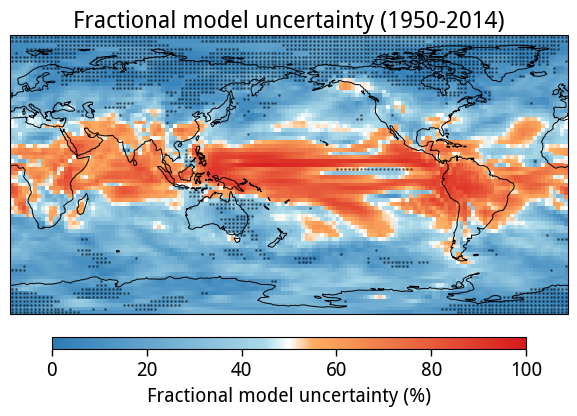

In [36]:
zz = (M_baseline / (M_baseline + I_baseline + 1e-12)) * 100

xx, yy = np.meshgrid(zz.lon, zz.lat)

T_baseline = M_baseline + I_baseline

fig = plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))

# ---------------------------
# Plot main field
# ---------------------------
im = zz.plot(
    ax=ax,
    vmin=0,
    vmax=100,
    cmap=cmap,
    transform=ccrs.PlateCarree(),
    cbar_kwargs=dict(
        orientation='horizontal',
        shrink=0.85,
        aspect=40,
        pad=0.05,
        label='Fractional model uncertainty (%)'
    )
)

# ---------------------------
# Stippling: low total uncertainty regions
# ---------------------------
low_unc = T_baseline < np.nanpercentile(T_baseline, 20)

ax.scatter(
    xx[low_unc],
    yy[low_unc],
    s=1,
    color='k',
    alpha=0.4,
    transform=ccrs.PlateCarree(),
    zorder=5
)

# ---------------------------
# Map aesthetics
# ---------------------------
ax.coastlines(linewidth=0.7)
ax.set_global()
ax.set_title('Fractional model uncertainty (1950-2014)')

plt.tight_layout()
plt.show()



# NOTE -  Stippling indicates regions where total uncertainty (M + I) lies in the lowest quintile of the domain distribution, representing areas where fractional partitioning is less informative due to weak overall uncertainty magnitude

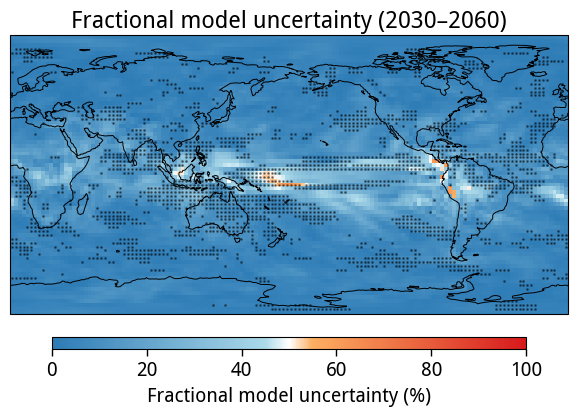

In [37]:
zz = (M_midc / (M_midc + I_midc + 1e-12)) * 100

xx, yy = np.meshgrid(zz.lon, zz.lat)

T_midc = M_midc + I_midc

fig = plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))

# ---------------------------
# Plot main field
# ---------------------------
im = zz.plot(
    ax=ax,
    vmin=0,
    vmax=100,
    cmap=cmap,
    transform=ccrs.PlateCarree(),
    cbar_kwargs=dict(
        orientation='horizontal',
        shrink=0.85,
        aspect=40,
        pad=0.05,
        label='Fractional model uncertainty (%)'
    )
)

# ---------------------------
# Stippling: low total uncertainty regions
# ---------------------------
low_unc = T_midc < np.nanpercentile(T_midc, 20)

ax.scatter(
    xx[low_unc],
    yy[low_unc],
    s=1,
    color='k',
    alpha=0.4,
    transform=ccrs.PlateCarree(),
    zorder=5
)

# ---------------------------
# Map aesthetics
# ---------------------------
ax.coastlines(linewidth=0.7)
ax.set_global()
ax.set_title('Fractional model uncertainty (2030–2060)')

plt.tight_layout()
plt.show()



# NOTE -  Stippling indicates regions where total uncertainty (M + I) lies in the lowest quintile of the domain distribution, representing areas where fractional partitioning is less informative due to weak overall uncertainty magnitude

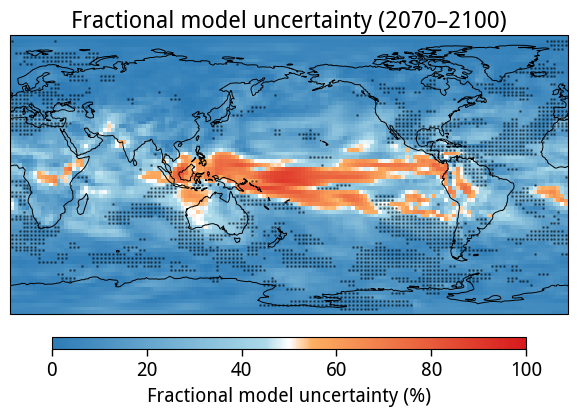

In [38]:
zz = (M_endc / (M_endc + I_endc + 1e-12)) * 100

xx, yy = np.meshgrid(zz.lon, zz.lat)

T_endc = M_endc + I_endc

fig = plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))

# ---------------------------
# Plot main field
# ---------------------------
im = zz.plot(
    ax=ax,
    vmin=0,
    vmax=100,
    cmap=cmap,
    transform=ccrs.PlateCarree(),
    cbar_kwargs=dict(
        orientation='horizontal',
        shrink=0.85,
        aspect=40,
        pad=0.05,
        label='Fractional model uncertainty (%)'
    )
)

# ---------------------------
# Stippling: low total uncertainty regions
# ---------------------------
low_unc = T_endc < np.nanpercentile(T_endc, 20)

ax.scatter(
    xx[low_unc],
    yy[low_unc],
    s=1,
    color='k',
    alpha=0.4,
    transform=ccrs.PlateCarree(),
    zorder=5
)

# ---------------------------
# Map aesthetics
# ---------------------------
ax.coastlines(linewidth=0.7)
ax.set_global()
ax.set_title('Fractional model uncertainty (2070–2100)')

plt.tight_layout()
plt.show()



# NOTE -  Stippling indicates regions where total uncertainty (M + I) lies in the lowest quintile of the domain distribution, representing areas where fractional partitioning is less informative due to weak overall uncertainty magnitude

In [ ]:
plot_list = [
    (T_baseline) - ts_regr_cmip6_baseline.regr.var('model'),
    (T_midc) - ts_regr_cmip6_midc.regr.var('model'),
    (T_endc) - ts_regr_cmip6_endc.regr.var('model'),
]

titles_list = [
    'Baseline',
    'Mid century',
    'End century',
]

labels_list = [
    'a',
    'b',
    'c',
]

In [19]:
# ### Fractional model uncertainty in Base period and in mid century changes and end century changes

# xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
# plot_maps(xx, yy, plot_list, titles_list, labels_list, cmap='bwr', levels=np.linspace(-0.1, 0.1, 21), pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
#             nrows=1, ncols=3, figsize=(20,8), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.PlateCarree(central_longitude=180), 
#             cbar_kwargs=dict(orientation='horizontal', label='Relative uncertainty', aspect=45, shrink=0.5, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

In [ ]:
zz = ((T_midc) - ts_regr_cmip6_midc.regr.var('model'))*100

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -10, vmax=10, cmap='coolwarm_r', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Relative total uncertainty in SMILES (%)'), transform=ccrs.PlateCarree())


ax.set_title('2030-2060')
plot_background(ax)
plt.tight_layout()



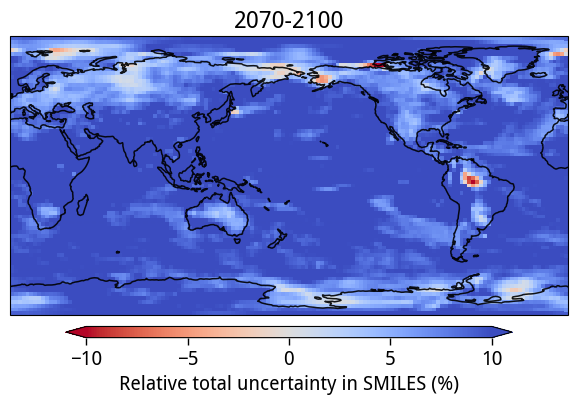

In [43]:
zz = ((T_endc) - ts_regr_cmip6_endc.regr.var('model'))*100

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -10, vmax=10, cmap='coolwarm_r', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Relative total uncertainty in SMILES (%)'), transform=ccrs.PlateCarree())


ax.set_title('2070-2100')
plot_background(ax)
plt.tight_layout()



### composite changes

In [19]:
base_path = "/g/data/if69/as8561/data/enso_tele_robustness"

smile_models = [
    'ACCESS-ESM1-5',
    'CESM1-CAM5',
    'CSIRO-Mk3-6-0',
    'CanESM2',
    'CanESM5_p1',
    'GFDL-CM3',
    'GFDL-ESM2M',
    'GFDL-SPEAR-MED',
    'MIROC6',
    'MPI-ESM',
]


In [20]:
from tqdm.auto import tqdm

In [21]:
# Observations / reanalysis
ds_rean  = xr.open_dataset(f"{base_path}/pr_rean_composites.nc")

# CMIP6
ds_cmip6 = xr.open_dataset(f"{base_path}/res/pr_enso_comp/cmip6_composites.nc")

# SMILEs
ds_smiles = {
    model: xr.open_dataset(f"{base_path}/res/pr_enso_comp/{model}_composites.nc")
    for model in smile_models
}

In [22]:
import xesmf as xe

In [23]:
regridder_rean = xe.Regridder(ds_rean, ds_cmip6, 'bilinear', periodic=True, ignore_degenerate=True)
# regridder_obs = xe.Regridder(ds_obs, ds_cmip6, 'bilinear', periodic=True, ignore_degenerate=True)

In [24]:
ds_rean_regrid = regridder_rean(ds_rean)
ds_rean_regrid

<xarray.Dataset> Size: 14MB
Dimensions:  (time: 115, lat: 72, lon: 144)
Coordinates:
  * time     (time) datetime64[ns] 920B 1900-06-01 1901-06-01 ... 2014-06-01
  * lon      (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
  * lat      (lat) float64 576B -88.75 -86.25 -83.75 ... 83.75 86.25 88.75
Data variables:
    en       (time, lat, lon) float32 5MB nan nan nan nan ... nan nan nan nan
    ln       (time, lat, lon) float32 5MB nan nan nan nan ... nan nan nan nan
    neut     (time, lat, lon) float32 5MB nan nan nan nan ... nan nan nan nan
Attributes:
    regrid_method:  bilinear

In [54]:
def calc_tele_composites(precip_el, precip_la, precip_ne,
                         duration=30, gap=2,
                         baseline_start=1950, baseline_end=2014):

    en_list, ln_list, neut_list = [], [], []
    en_n, ln_n, neut_n = [], [], []
    ey = []

    for yr in tqdm(range(baseline_start, baseline_end - duration + 1, gap),
                   desc="Computing composites"):
        win = slice(str(yr), str(yr + duration - 1))

        # def window_mean(da):
        #     subset = da.sel(time=win)
        #     n = subset.sizes["time"]
        #     if n == 0:
        #         return np.full(da.isel(time=0).shape, np.nan), 0
        #     return subset.mean("time").data, n
        def window_mean(da):
            subset = da.sel(time=slice(str(yr), str(yr + duration - 1)))
            subset = subset.dropna('time', how='all')  # drop non-EN years
            n = subset.sizes['time']
            if n == 0:
                return np.full(da.isel(time=0).shape, np.nan), 0
            return subset.mean('time').data, n

        en_data, n_en = window_mean(precip_el)
        ln_data, n_ln = window_mean(precip_la)
        neut_data, n_neut = window_mean(precip_ne)

        en_list.append(en_data)
        ln_list.append(ln_data)
        neut_list.append(neut_data)

        en_n.append(n_en)
        ln_n.append(n_ln)
        neut_n.append(n_neut)
        ey.append(yr + duration - 1)

    dims = ["ey", "lat", "lon"]
    return xr.Dataset(
        dict(
            en     = (dims, np.stack(en_list)),
            ln     = (dims, np.stack(ln_list)),
            neut   = (dims, np.stack(neut_list)),
            n_en   = ("ey", en_n),
            n_ln   = ("ey", ln_n),
            n_neut = ("ey", neut_n),
        ),
        coords=dict(lat=precip_el.lat, lon=precip_el.lon, ey=("ey", ey)),
        attrs=dict(baseline=f"{baseline_start}-{baseline_end}")
    )

In [55]:
ds_rean_regrid_roll = calc_tele_composites(
    precip_el   = ds_rean_regrid.en,
    precip_la   = ds_rean_regrid.ln,
    precip_ne   = ds_rean_regrid.neut,
    duration    = 30,
    gap         = 1,
    baseline_start = 1900,
    baseline_end   = 2014,
)

Computing composites:   0%|          | 0/85 [00:00<?, ?it/s]

In [56]:
# Baseline composite (full 1950-2014)
en_base_rean   = ds_rean_regrid.en.sel(time=slice('1950', '2014')).mean('time')
ln_base_rean   = ds_rean_regrid.ln.sel(time=slice('1950', '2014')).mean('time')

# Anomaly of each 30-year window from the baseline
en_anom_roll   = ds_rean_regrid_roll.en   - en_base_rean
ln_anom_roll   = ds_rean_regrid_roll.ln   - ln_base_rean

# Noise = std of those anomalies across windows
noise_en_obs   = en_anom_roll.std('ey')
noise_ln_obs   = ln_anom_roll.std('ey')

In [57]:
en_anom_roll

<xarray.DataArray 'en' (ey: 85, lat: 72, lon: 144)> Size: 4MB
array([[[-0.1994348 , -0.20265481, -0.2016083 , ..., -0.19013776,
         -0.19453713, -0.19941346],
        [-0.6089636 , -0.60605645, -0.6158308 , ..., -0.5872792 ,
         -0.59267974, -0.60391885],
        [-0.7172035 , -0.7207242 , -0.71771383, ..., -0.7331495 ,
         -0.734857  , -0.72119987],
        ...,
        [-0.40534365, -0.34790677, -0.31629047, ..., -0.59502983,
         -0.5343009 , -0.47001567],
        [-0.5545817 , -0.5448512 , -0.5361969 , ..., -0.56908596,
         -0.564512  , -0.55850273],
        [-0.63398695, -0.6310234 , -0.62476575, ..., -0.638404  ,
         -0.6396681 , -0.6382916 ]],

       [[-0.19389185, -0.19717288, -0.196442  , ..., -0.1827962 ,
         -0.18798782, -0.19401716],
        [-0.60218596, -0.5934109 , -0.5994748 , ..., -0.57752335,
         -0.5835922 , -0.59494406],
        [-0.71006376, -0.7075982 , -0.70405364, ..., -0.7270136 ,
         -0.73015845, -0.71675617],
...
        [-0.30575454, -0.29538542, -0.27484015, ..., -0.31685975,
         -0.305617  , -0.31158003],
        [-0.4787401 , -0.47621563, -0.4731893 , ..., -0.48920757,
         -0.48577523, -0.48282576],
        [-0.17278773, -0.17207408, -0.17242788, ..., -0.17424624,
         -0.174157  , -0.17381036]],

       [[-0.6399787 , -0.6437504 , -0.64843464, ..., -0.63992697,
         -0.63966125, -0.6427319 ],
        [-0.66460216, -0.6703842 , -0.67615247, ..., -0.6603084 ,
         -0.6625706 , -0.66140676],
        [-0.52065736, -0.5403045 , -0.54778653, ..., -0.49222147,
         -0.49958903, -0.50871676],
        ...,
        [-0.30575454, -0.29538542, -0.27484015, ..., -0.31685975,
         -0.305617  , -0.31158003],
        [-0.4787401 , -0.47621563, -0.4731893 , ..., -0.48920757,
         -0.48577523, -0.48282576],
        [-0.17278773, -0.17207408, -0.17242788, ..., -0.17424624,
         -0.174157  , -0.17381036]]], dtype=float32)
Coordinates:
  * lat      (lat) float64 576B -88.75 -86.25 -83.75 ... 83.75 86.25 88.75
  * lon      (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
  * ey       (ey) int64 680B 1929 1930 1931 1932 1933 ... 2010 2011 2012 2013

In [58]:
# Per-model future and baseline composites
en_fut_models  = ds_cmip6.en.sel(time=slice('2070', '2100')).mean('time')   # (model, lat, lon)
en_base_models = ds_cmip6.en.sel(time=slice('1950', '2014')).mean('time')   # (model, lat, lon)

ln_fut_models  = ds_cmip6.ln.sel(time=slice('2070', '2100')).mean('time')
ln_base_models = ds_cmip6.ln.sel(time=slice('1950', '2014')).mean('time')

# T-test across model dimension
pval_en_cmip6 = xr.apply_ufunc(
    lambda fut, base: stats.ttest_rel(fut, base).pvalue,
    en_fut_models, en_base_models,
    input_core_dims=[['model'], ['model']],
    vectorize=True,
    dask='allowed'
)

pval_ln_cmip6 = xr.apply_ufunc(
    lambda fut, base: stats.ttest_rel(fut, base).pvalue,
    ln_fut_models, ln_base_models,
    input_core_dims=[['model'], ['model']],
    vectorize=True,
    dask='allowed'
)

# Signal = MMM change
signal_en_cmip6 = (en_fut_models - en_base_models).mean('model')
signal_ln_cmip6 = (ln_fut_models - ln_base_models).mean('model')

# Masks
mask_en_cmip6_pval = pval_en_cmip6 < 0.05
mask_ln_cmip6_pval = pval_ln_cmip6 < 0.05

In [59]:
snr_en_cmip6_obs = signal_en_cmip6 / noise_en_obs
snr_ln_cmip6_obs = signal_ln_cmip6 / noise_ln_obs

# Robust where S/N > 1.5
mask_en_cmip6_obs = snr_en_cmip6_obs > 1.5
mask_ln_cmip6_obs = snr_ln_cmip6_obs > 1.5

In [60]:
iv_en_list, iv_ln_list = [], []

for model in tqdm(smile_models, desc="Computing SMILE IV"):
    ds = ds_smiles[model]
    
    # Ensemble mean of baseline composite per member
    en_base = ds.en.sel(time=slice('1950', '2014')).mean('time')  # (member, lat, lon)
    ln_base = ds.ln.sel(time=slice('1950', '2014')).mean('time')
    
    # Spread across ensemble members = internal variability
    iv_en_list.append(en_base.std('model'))
    iv_ln_list.append(ln_base.std('model'))

# Average IV across SMILE models
iv_en_smile = xr.concat(iv_en_list, dim='smile_model', coords='minimal').mean('smile_model')
iv_ln_smile = xr.concat(iv_ln_list, dim='smile_model', coords='minimal').mean('smile_model')

Computing SMILE IV:   0%|          | 0/10 [00:00<?, ?it/s]

In [61]:
sig_en_list, sig_ln_list = [], []

for model in tqdm(smile_models, desc="Computing SMILE signal"):
    ds = ds_smiles[model]
    
    # Ensemble mean future minus baseline per model
    en_fut  = ds.en.sel(time=slice('2070', '2100')).mean('time').mean('model')
    en_base = ds.en.sel(time=slice('1950', '2014')).mean('time').mean('model')
    
    ln_fut  = ds.ln.sel(time=slice('2070', '2100')).mean('time').mean('model')
    ln_base = ds.ln.sel(time=slice('1950', '2014')).mean('time').mean('model')
    
    sig_en_list.append(en_fut - en_base)
    sig_ln_list.append(ln_fut - ln_base)

# Average signal across SMILE models
signal_en_smile = xr.concat(sig_en_list, dim='smile_model', coords='minimal').mean('smile_model')
signal_ln_smile = xr.concat(sig_ln_list, dim='smile_model', coords='minimal').mean('smile_model')

Computing SMILE signal:   0%|          | 0/10 [00:00<?, ?it/s]

In [62]:
# SMILE IV based S/N
snr_en_smile = signal_en_smile / iv_en_smile
snr_ln_smile = signal_ln_smile / iv_ln_smile

# Masks
mask_en_smile = snr_en_smile > 1.5
mask_ln_smile = snr_ln_smile > 1.5

In [63]:
snr_en_smile

<xarray.DataArray 'en' (lat: 72, lon: 144)> Size: 83kB
array([[-0.07659589, -0.06160042, -0.05132182, ..., -0.10656057,
        -0.09713491, -0.09358138],
       [ 0.21193007,  0.23243897,  0.25375884, ...,  0.14722352,
         0.16157441,  0.17078105],
       [ 0.56497638,  0.60797545,  0.64775398, ...,  0.44349877,
         0.48074824,  0.50341833],
       ...,
       [-0.55976914, -0.51475851, -0.47152905, ..., -0.6181235 ,
        -0.58748569, -0.57366187],
       [-0.69546396, -0.69670738, -0.69449549, ..., -0.67960583,
        -0.69499345, -0.69979293],
       [-0.89254546, -0.8917541 , -0.87724702, ..., -0.89088101,
        -0.89751216, -0.89363413]])
Coordinates:
  * lon      (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
  * lat      (lat) float64 576B -88.75 -86.25 -83.75 ... 83.75 86.25 88.75
    height   float64 8B 2.0

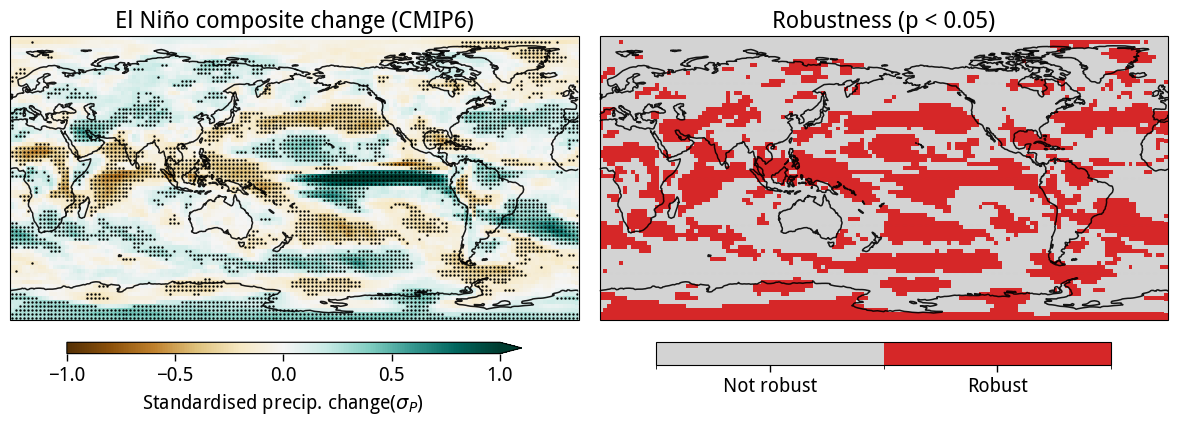

In [64]:
# El Niño
plot_teleconnection_robustness(
    field        = signal_en_cmip6,
    lon          = signal_en_cmip6.lon.values,
    lat          = signal_en_cmip6.lat.values,
    pval_model   = pval_en_cmip6,
    use_pval     = True,
    title_main   = 'El Niño composite change (CMIP6)',
    title_suffix = 'Robustness (p < 0.05)',
    cbar_label   = 'Standardised precip. change($\sigma_P$)',
    cmap = 'BrBG',
    vmin=-1.0, vmax=1.0,
)

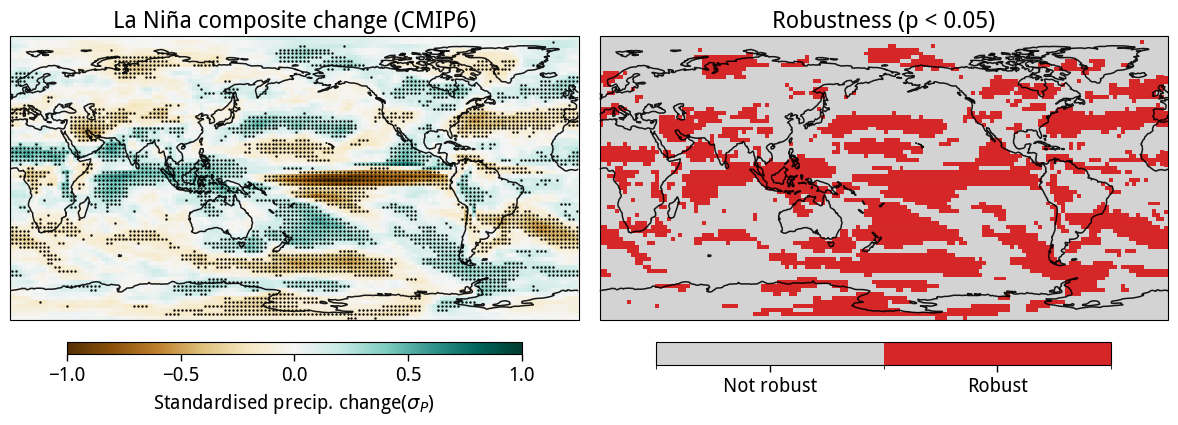

In [65]:
# La Niña
plot_teleconnection_robustness(
    field        = signal_ln_cmip6,
    lon          = signal_ln_cmip6.lon.values,
    lat          = signal_ln_cmip6.lat.values,
    pval_model   = pval_ln_cmip6,
    use_pval     = True,
    title_main   = 'La Niña composite change (CMIP6)',
    title_suffix = 'Robustness (p < 0.05)',
    cbar_label   = 'Standardised precip. change($\sigma_P$)',
    cmap = 'BrBG',
    vmin=-1.0, vmax=1.0,
)

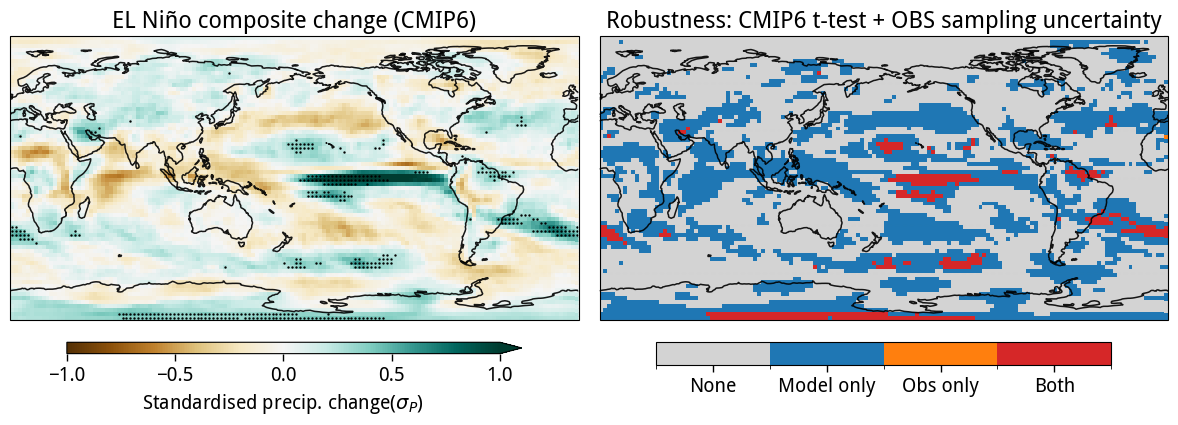

In [66]:
# El Niño
plot_teleconnection_robustness(
    field        = signal_en_cmip6,
    lon          = signal_en_cmip6.lon.values,
    lat          = signal_en_cmip6.lat.values,
    pval_model   = pval_en_cmip6,
    snr_obs      = snr_en_cmip6_obs,
    use_pval     = True,
    title_main   = 'EL Niño composite change (CMIP6)',
    title_suffix = 'Robustness: CMIP6 t-test + OBS sampling uncertainty',
    cbar_label   = 'Standardised precip. change($\sigma_P$)',
    cmap = 'BrBG',
    vmin=-1.0, vmax=1.0,
)

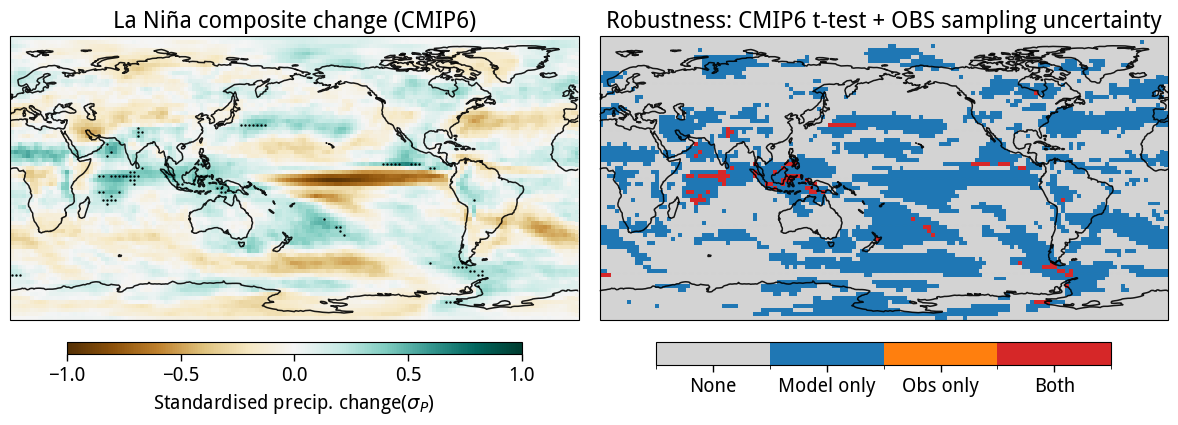

In [67]:
# La Niña
plot_teleconnection_robustness(
    field        = signal_ln_cmip6,
    lon          = signal_ln_cmip6.lon.values,
    lat          = signal_ln_cmip6.lat.values,
    pval_model   = pval_ln_cmip6,
    snr_obs      = snr_ln_cmip6_obs,
    use_pval     = True,
    title_main   = 'La Niña composite change (CMIP6)',
    title_suffix = 'Robustness: CMIP6 t-test + OBS sampling uncertainty',
    cbar_label   = 'Standardised precip. change($\sigma_P$)',
    cmap = 'BrBG',
    vmin=-1.0, vmax=1.0,
)

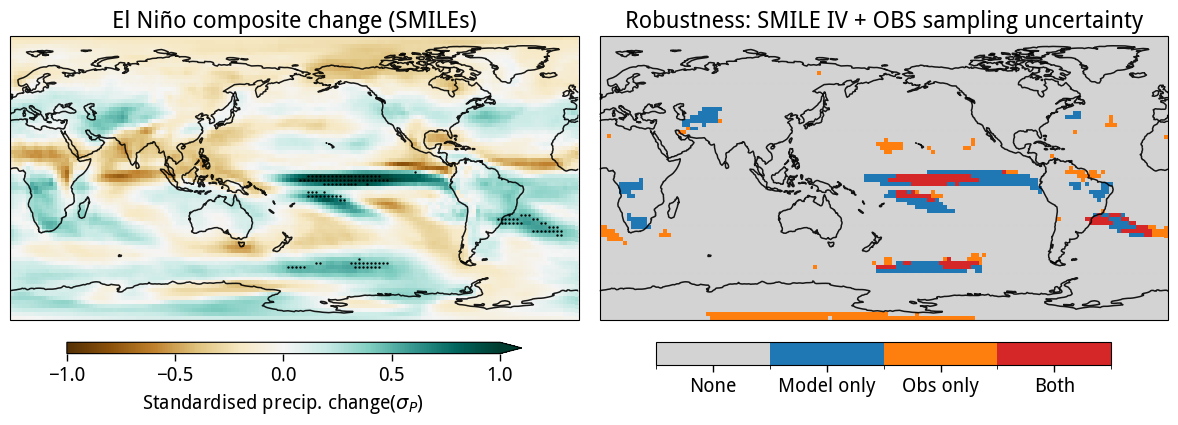

In [68]:
# El Niño
plot_teleconnection_robustness(
    field        = signal_en_smile,
    lon          = signal_en_smile.lon.values,
    lat          = signal_en_smile.lat.values,
    snr_model    = snr_en_smile,
    snr_obs      = snr_en_cmip6_obs,
    use_pval     = False,
    title_main   = 'El Niño composite change (SMILEs)',
    title_suffix = 'Robustness: SMILE IV + OBS sampling uncertainty',
    cbar_label   = 'Standardised precip. change($\sigma_P$)',
    cmap = 'BrBG',
    vmin=-1.0, vmax=1.0,
)

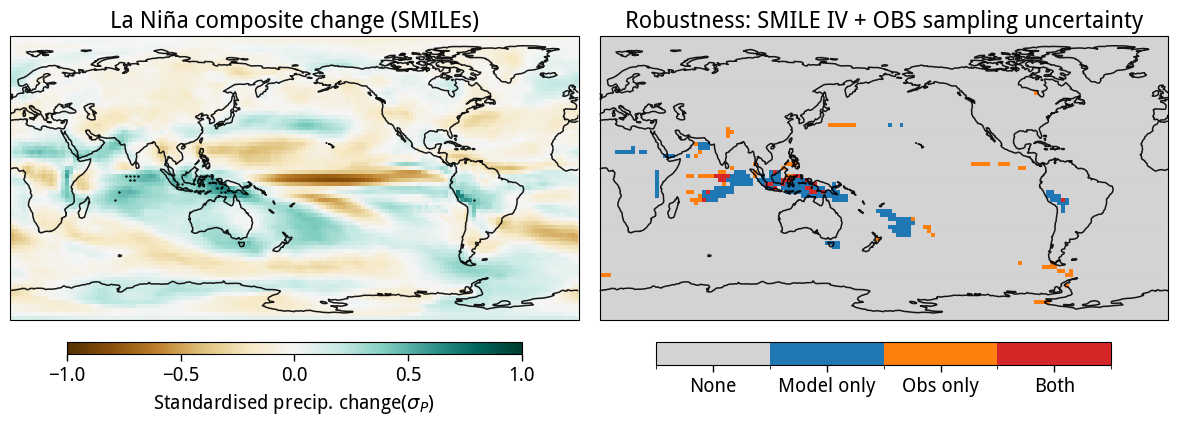

In [69]:
# La Niña
plot_teleconnection_robustness(
    field        = signal_ln_smile,
    lon          = signal_ln_smile.lon.values,
    lat          = signal_ln_smile.lat.values,
    snr_model    = snr_ln_smile,
    snr_obs      = snr_ln_cmip6_obs,
    use_pval     = False,
    title_main   = 'La Niña composite change (SMILEs)',
    title_suffix = 'Robustness: SMILE IV + OBS sampling uncertainty',
    cbar_label   = 'Standardised precip. change($\sigma_P$)',
    cmap = 'BrBG',
    vmin=-1.0, vmax=1.0,
)

In [70]:
def plot_enso_agreement(mask_en, mask_ln, lon, lat, title=''):
    
    # 0: neither, 1: EN only, 2: LN only, 3: both
    cat = mask_en.astype(int) + 2 * mask_ln.astype(int)
    
    cmap_cat = mcolors.ListedColormap([
        'lightgrey',    # neither
        'tab:blue',     # EN only
        'tab:orange',   # LN only
        'tab:red',      # both
    ])
    bounds = [0, 1, 2, 3, 4]
    ticks  = [0.5, 1.5, 2.5, 3.5]
    labels = ['Neither', 'EN only', 'LN only', 'Both']
    norm   = mcolors.BoundaryNorm(bounds, cmap_cat.N)

    xx, yy = np.meshgrid(lon, lat)

    fig, ax = plt.subplots(
        subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180)),
        figsize=(10, 4)
    )

    im = ax.pcolormesh(xx, yy, cat,
                       cmap=cmap_cat, norm=norm,
                       transform=ccrs.PlateCarree())

    cbar = plt.colorbar(im, ax=ax, orientation='horizontal',
                        pad=0.05, shrink=0.8, fraction=0.07)
    cbar.set_ticks(ticks)
    cbar.set_ticklabels(labels)

    ax.set_title(title)
    plot_background(ax)
    plt.tight_layout()

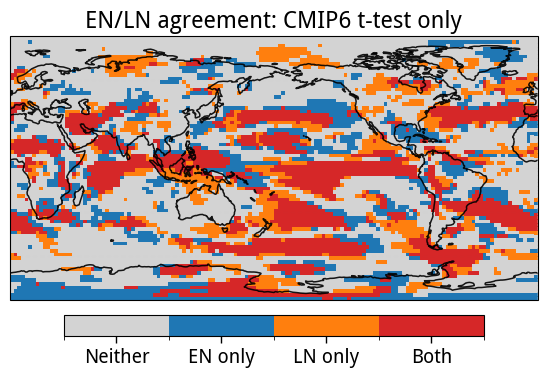

In [75]:
# 1. CMIP6 t-test only
plot_enso_agreement(
    mask_en = mask_en_cmip6_pval,
    mask_ln = mask_ln_cmip6_pval,
    lon     = signal_en_cmip6.lon.values,
    lat     = signal_en_cmip6.lat.values,
    title   = 'EN/LN agreement: CMIP6 t-test only'
)

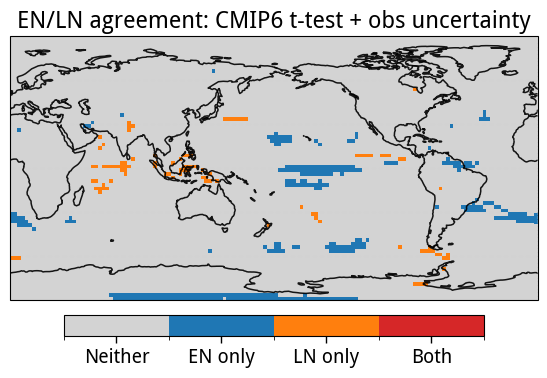

In [76]:
# 2. CMIP6 t-test + obs uncertainty
plot_enso_agreement(
    mask_en = mask_en_cmip6_pval & mask_en_cmip6_obs,
    mask_ln = mask_ln_cmip6_pval & mask_ln_cmip6_obs,
    lon     = signal_en_cmip6.lon.values,
    lat     = signal_en_cmip6.lat.values,
    title   = 'EN/LN agreement: CMIP6 t-test + obs uncertainty'
)


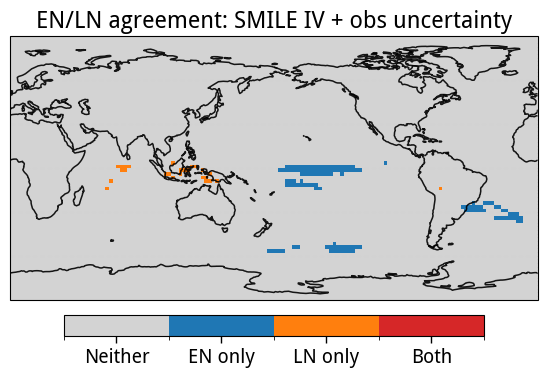

In [77]:
# 3. SMILE S/N + obs uncertainty
plot_enso_agreement(
    mask_en = mask_en_smile & mask_en_cmip6_obs,
    mask_ln = mask_ln_smile & mask_ln_cmip6_obs,
    lon     = signal_en_smile.lon.values,
    lat     = signal_en_smile.lat.values,
    title   = 'EN/LN agreement: SMILE IV + obs uncertainty'
)

In [74]:
ds_rean_regrid_roll.n_en

<xarray.DataArray 'n_en' (ey: 85)> Size: 680B
array([6, 7, 7, 6, 6, 5, 4, 4, 4, 4, 4, 5, 6, 6, 6, 5, 5, 5, 5, 4, 4, 4,
       5, 5, 5, 5, 4, 4, 5, 5, 5, 4, 4, 4, 4, 4, 5, 5, 5, 6, 6, 5, 4, 5,
       5, 5, 5, 5, 5, 5, 5, 5, 4, 5, 5, 5, 5, 6, 5, 5, 5, 5, 6, 6, 6, 6,
       5, 5, 6, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 6, 6, 6, 5, 5])
Coordinates:
  * ey       (ey) int64 680B 1929 1930 1931 1932 1933 ... 2010 2011 2012 2013

In [89]:
# Baseline asymmetry
asym_base_rean  = (ds_rean.en.mean('time') + ds_rean.ln.mean('time')) / 2
asym_base_cmip6 = (en_base_models.mean('model') + ln_base_models.mean('model')) / 2

# Future change in asymmetry
asym_fut_cmip6  = (en_fut_models.mean('model') + ln_fut_models.mean('model')) / 2
asym_change     = asym_fut_cmip6 - asym_base_cmip6

# SMILE change in asymmetry
asym_change_smile = (signal_en_smile + signal_ln_smile) / 2

In [90]:
# Panel 3 — CMIP6 t-test
both_p3  = mask_en_cmip6_pval & mask_ln_cmip6_pval
xor_p3   = mask_en_cmip6_pval ^ mask_ln_cmip6_pval

# Panel 4 — CMIP6 t-test + obs
mask_en_p4 = mask_en_cmip6_pval & mask_en_cmip6_obs
mask_ln_p4 = mask_ln_cmip6_pval & mask_ln_cmip6_obs
both_p4    = mask_en_p4 & mask_ln_p4
xor_p4     = mask_en_p4 ^ mask_ln_p4

# Panel 5 — SMILE IV + obs
mask_en_p5 = mask_en_smile & mask_en_cmip6_obs
mask_ln_p5 = mask_ln_smile & mask_ln_cmip6_obs
both_p5    = mask_en_p5 & mask_ln_p5
xor_p5     = mask_en_p5 ^ mask_ln_p5

In [103]:
def plot_asymmetry(field, lon, lat,
                   mask_both=None, mask_xor=None,
                   contour_field=None,
                   title='', cbar_label='',
                   vmin=None, vmax=None,
                   cmap='BrBG'):

    xx, yy = np.meshgrid(lon, lat)

    fig, ax = plt.subplots(
        subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180)),
        figsize=(10, 4)
    )

    # Main field
    im = ax.pcolormesh(
        xx, yy, field,
        cmap=cmap, vmin=vmin, vmax=vmax,
        transform=ccrs.PlateCarree()
    )

    # Baseline contours if provided
    if contour_field is not None:
        ax.contour(
            xx, yy, contour_field,
            levels=6,
            colors='k', linewidths=0.6, alpha=0.5,
            transform=ccrs.PlateCarree()
        )

    # Dots — both EN and LN robust
    if mask_both is not None:
        ax.scatter(
            xx[mask_both], yy[mask_both],
            s=1.5, color='k', marker='.',
            transform=ccrs.PlateCarree(),
            label='Both robust'
        )

    # Crosses — only one phase robust
    if mask_xor is not None:
        ax.scatter(
            xx[mask_xor], yy[mask_xor],
            s=1.5, color='k', marker='x',
            transform=ccrs.PlateCarree(),
            label='One phase only'
        )

    # Colorbar tied to axes width
    cbar = plt.colorbar(im, ax=ax, orientation='horizontal',
                        pad=0.05, fraction=0.046, aspect=30)
    cbar.set_label(cbar_label)

    ax.set_title(title)
    plot_background(ax)
    plt.tight_layout()

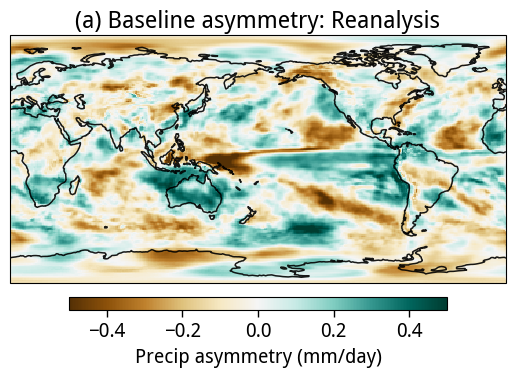

In [109]:
vmin, vmax = -0.5, 0.5   # adjust to your data range

# Panel 1 — Baseline asymmetry reanalysis
plot_asymmetry(
    field       = asym_base_rean,
    lon         = ds_rean.lon.values,
    lat         = ds_rean.lat.values,
    title       = '(a) Baseline asymmetry: Reanalysis',
    cbar_label  = 'Precip asymmetry (mm/day)',
    vmin=vmin, vmax=vmax
)


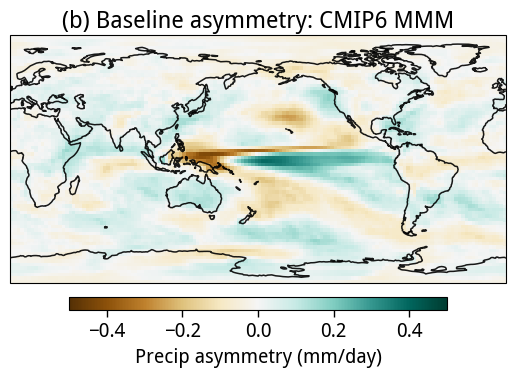

In [110]:
# Panel 2 — Baseline asymmetry CMIP6
plot_asymmetry(
    field       = asym_base_cmip6,
    lon         = signal_en_cmip6.lon.values,
    lat         = signal_en_cmip6.lat.values,
    title       = '(b) Baseline asymmetry: CMIP6 MMM',
    cbar_label  = 'Precip asymmetry (mm/day)',
    vmin=vmin, vmax=vmax
)


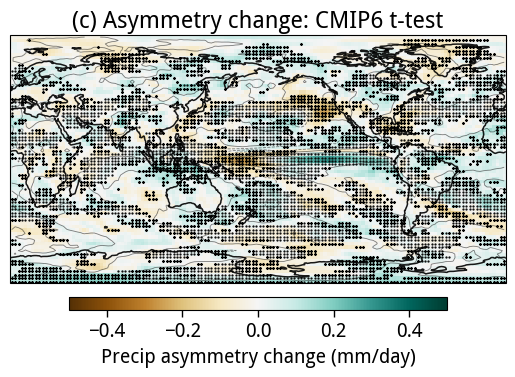

In [111]:
# Panel 3 — Change in asymmetry + CMIP6 t-test
plot_asymmetry(
    field          = asym_change,
    lon            = signal_en_cmip6.lon.values,
    lat            = signal_en_cmip6.lat.values,
    mask_both      = both_p3.values,
    mask_xor       = xor_p3.values,
    contour_field  = asym_base_cmip6.values,
    title          = '(c) Asymmetry change: CMIP6 t-test',
    cbar_label     = 'Precip asymmetry change (mm/day)',
    vmin=vmin, vmax=vmax
)

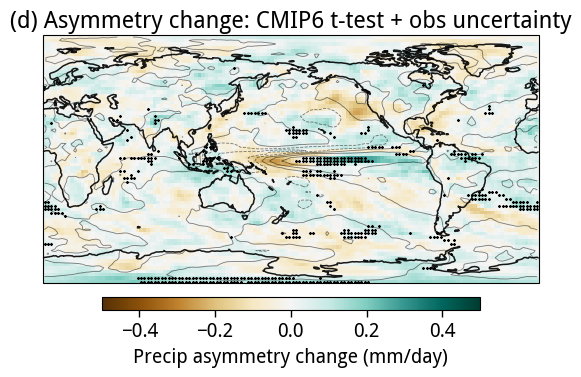

In [112]:

# Panel 4 — Change in asymmetry + CMIP6 t-test + obs
plot_asymmetry(
    field          = asym_change,
    lon            = signal_en_cmip6.lon.values,
    lat            = signal_en_cmip6.lat.values,
    mask_both      = both_p4.values,
    mask_xor       = xor_p4.values,
    contour_field  = asym_base_cmip6.values,
    title          = '(d) Asymmetry change: CMIP6 t-test + obs uncertainty',
    cbar_label     = 'Precip asymmetry change (mm/day)',
    vmin=vmin, vmax=vmax
)

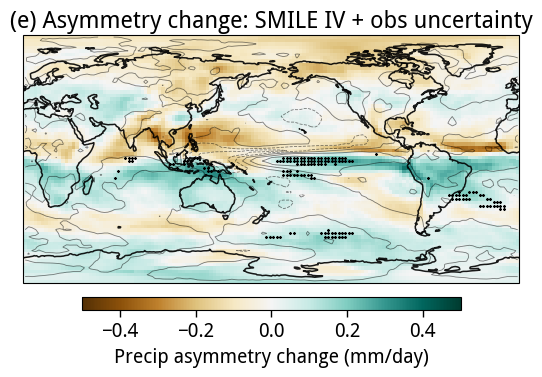

In [113]:

# Panel 5 — Change in asymmetry + SMILE IV + obs
plot_asymmetry(
    field          = asym_change_smile,
    lon            = signal_en_smile.lon.values,
    lat            = signal_en_smile.lat.values,
    mask_both      = both_p5.values,
    mask_xor       = xor_p5.values,
    contour_field  = asym_base_cmip6.values,
    title          = '(e) Asymmetry change: SMILE IV + obs uncertainty',
    cbar_label     = 'Precip asymmetry change (mm/day)',
    vmin=vmin, vmax=vmax
)